# LEVELS Benchmark — Cross-Level Summary

Loads the newest saved results of each level notebook (no agent runs happen here) and answers the cross-level research questions: RQ1 productivity, RQ2 performance vs. complexity, RQ3/RQ7 checkpoint opportunities, RQ4 calibration, RQ5 failure attribution. Pass `run_id=` to `load_results` to pin a specific run.

In [1]:
from levels_bench import init, load_results, results_to_dataframe, save_results, reports

init(load_key=False)

LABELS = ["level1_atomic", "level2_workflow", "level3_discovery", "calibration"]
all_results = []
for label in LABELS:
    try:
        all_results += load_results(label)
    except FileNotFoundError as e:
        print(f"skipping: {e}")
summary_df = results_to_dataframe(all_results)
print(f"{len(summary_df)} results from {summary_df['model'].n_unique() if len(summary_df) else 0} models")

Working directory: /Users/hhn/lanl/dsi/tools/ai_search
Run id: 20261022_072215 | models: ['aws-gov.gpt-5.4', 'anthropic.claude-sonnet-4-5-20250929-v1:0'] | judges: ['aws-gov.gpt-5.4', 'anthropic.claude-sonnet-4-5-20250929-v1:0']
Workers: 4 | turn timeout: 180s | skip_network: False
Loaded: /Users/hhn/lanl/dsi/tools/ai_search/levels_benchmark_results/20261022_062810_level1_atomic.json
Loaded: /Users/hhn/lanl/dsi/tools/ai_search/levels_benchmark_results/20261022_063223_level2_workflow.json
skipping: No saved results for label 'level3_discovery' in /Users/hhn/lanl/dsi/tools/ai_search/levels_benchmark_results
skipping: No saved results for label 'calibration' in /Users/hhn/lanl/dsi/tools/ai_search/levels_benchmark_results
50 results from 2 models


### RQ2 — Pass rate / score / efficiency / latency by complexity level and model

pass_rate  avg_score  \
model                                     level                         
anthropic.claude-sonnet-4-5-20250929-v1:0 1           1.00       1.00   
                                          2           0.92       0.91   
aws-gov.gpt-5.4                           1           0.77       0.97   
                                          2           0.75       0.81   

                                                 avg_efficiency  \
model                                     level                   
anthropic.claude-sonnet-4-5-20250929-v1:0 1                0.46   
                                          2                0.44   
aws-gov.gpt-5.4                           1                0.49   
                                          2                0.49   

                                                 avg_elapsed_sec  avg_tokens  \
model                                     level                                
anthropic.claude-sonnet-4-5-20250929-v1:0 1                11.98     4346.77   
                                          2                16.18     5623.67   
aws-gov.gpt-5.4                           1                 3.97     2194.00   
                                          2                 5.82     3048.17   

                                                 n_tasks  
model                                     level           
anthropic.claude-sonnet-4-5-20250929-v1:0 1           13  
                                          2           12  
aws-gov.gpt-5.4                           1           13  
                                          2           12

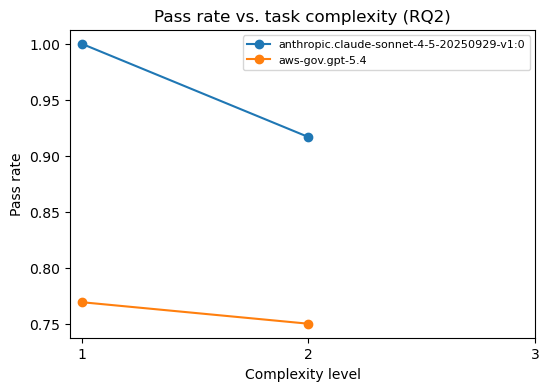

### RQ5 — Failure-category distribution by model

failure_category,MODEL_REASONING,TOOL_FRAMEWORK,UNKNOWN
model,,,
anthropic.claude-sonnet-4-5-20250929-v1:0,0,0,1
aws-gov.gpt-5.4,4,1,1


### RQ3/RQ7 — Checkpoint-opportunity counts vs. outcome

,avg_checkpoint_opportunities,avg_high_stakes_actions,avg_hedge_language,pass_rate
model,,,,
anthropic.claude-sonnet-4-5-20250929-v1:0,0.44,0.32,0.12,0.96
aws-gov.gpt-5.4,0.16,0.12,0.04,0.76


### RQ1 — Productivity vs. human baseline

No reference_time_sec set on any task yet; a human must time each task's reference_path once (see BENCHMARK_METHODOLOGY.md, RQ1).


""


In [2]:
reports.research_questions(summary_df)

In [3]:
summary_df

,model,task_id,query,prompt_style,base_task_id,level,category,status,passed,score,...,check_args_ok,check_path_ok,check_quant_ok,check_keyword_ok,check_forbidden_ok,check_nonempty_ok,judge_efficiency_score,judge_efficiency_reasoning,judge_process_quality_score,judge_process_quality_reasoning
0,aws-gov.gpt-5.4,L1_load_ocean11,Load the ocean_11_datasets.db database.,standard,L1_load_ocean11,1,Data Access,PASS,True,1.000,...,True,True,True,True,True,True,0.175,[aws-gov.gpt-5.4] The reference needed a singl...,NaN,NaN
1,aws-gov.gpt-5.4,L1_load_nif_direct,Load the nif.db database.,standard,L1_load_nif_direct,1,Data Access,PASS,True,1.000,...,True,True,True,True,True,True,0.400,[aws-gov.gpt-5.4] The agent successfully loade...,NaN,NaN
2,aws-gov.gpt-5.4,L1_load_poisson,Load the poisson.db database.,standard,L1_load_poisson,1,Data Access,PASS,True,1.000,...,True,True,True,True,True,True,0.400,[aws-gov.gpt-5.4] The agent successfully loade...,NaN,NaN
3,aws-gov.gpt-5.4,L1_search_implosion,Do you have any implosion data in oceans 11 da...,standard,L1_search_implosion,1,Data Discovery,PASS,True,1.000,...,True,True,True,True,True,True,0.610,[aws-gov.gpt-5.4] The agent completed the task...,NaN,NaN
4,aws-gov.gpt-5.4,L1_download_nif_sim,Download the simulation data for sim name: nif...,standard,L1_download_nif_sim,1,Data Retrieval,FAIL,False,0.857,...,True,True,True,True,True,True,0.075,[aws-gov.gpt-5.4] The agent never reached the ...,NaN,NaN
5,aws-gov.gpt-5.4,L1_store_poisson_hdf5,Download this simulation data file: https://oc...,standard,L1_store_poisson_hdf5,1,Data Retrieval,PASS,True,1.000,...,True,True,True,True,True,True,0.475,[aws-gov.gpt-5.4] The agent completed the down...,NaN,NaN
6,aws-gov.gpt-5.4,L1_owner_field,"Who is the owner of the NIF dataset""",standard,L1_owner_field,1,Metadata Query,FAIL,False,0.857,...,True,True,True,False,True,True,0.925,[aws-gov.gpt-5.4] The agent used essentially t...,NaN,NaN
7,aws-gov.gpt-5.4,L1_extract_dataset_count,How many datasets are in the Ocean 11 catalog?,standard,L1_extract_dataset_count,1,Data Exploration,PASS,True,1.000,...,True,True,True,True,True,True,1.000,[aws-gov.gpt-5.4] The agent directly executed ...,NaN,NaN
8,aws-gov.gpt-5.4,L1_extract_originating_org,What organization is listed for the Ocean 11 d...,standard,L1_extract_originating_org,1,Metadata Query,PASS,True,1.000,...,True,True,True,True,True,True,0.980,[aws-gov.gpt-5.4] The agent effectively matche...,NaN,NaN
9,aws-gov.gpt-5.4,L1_extract_physics_theme_count,How many datasets are categorized as physics?,standard,L1_extract_physics_theme_count,1,Metadata Query,PASS,True,1.000,...,True,True,True,True,True,True,0.950,[aws-gov.gpt-5.4] The agent used a single data...,NaN,NaN


In [4]:
# save_results(all_results, "all_levels_summary")